In [34]:
from pathlib import Path 
import json, inspect, time, warnings 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import torch 
from torch import nn 
from scipy.stats import qmc, norm 

try: 
    import QuantLib as ql 
except ImportError as exc: 
    raise ImportError("Install QuantLib") from exc 

DEVICE = torch.device('cpu')
torch.set_num_threads(1)
print('torch:', torch.__version__, '| QuantLib:', getattr(ql, '__version__', 'unknown'))

torch: 1.12.1 | QuantLib: 1.43


In [35]:
FEATURES = ['S0', 'K', 'T', 'r', 'v0', 'kappa', 'theta', 'sigma', 'rho']
BOUNDS = {
    'S0':(0.6, 1.4),
    'T': (0.1, 1.4),
    'r': (0.0, 0.1),
    'v0': (0.05, 0.5),
    'kappa': (0.0, 2.0),
    'theta': (0.0, 0.5),
    'sigma': (0.0, 0.5),
    'rho': (-0.95, 0.0)
}
TRAIN_N = 12000
MODEL_SEEDS = (42, 43, 44)
K_FIXED = 1.0 
Q_FIXED = 0.0 
INTEGRATION_ORDER = 128 
VALUATION = ql.Date(2, ql.January, 2026)
SEED_BASE = 20261119
REFERENCE_CHECK_ORDER = 64 
REFERENCE_CHECK_TOL = 1e-5
N_BOOTSTRAP = 1000 
N_PER_REGIME = 200 
N_CONTROL = 500 
INCLUDE_OPTIONAL_MLP = True 

ROOT = Path.cwd()
MODEL_COMPARISON_MODEL_DIR = ROOT / 'experiment_model_comparison_results' / f'n{TRAIN_N}' / 'models' 
ARCHITECTURE_MODEL_DIR = ROOT / 'experiment_model_comparison_results' / f'n{TRAIN_N}' / 'models'
EXTRA_MODEL_DIRS = [ROOT, Path('/mnt/data')]
OUTPUT_DIR = ROOT / 'experiment_robustness' / f'n{TRAIN_N}'/ f'nregime{N_PER_REGIME}_control{N_CONTROL}'
DATA_DIR = OUTPUT_DIR / 'regime_data'
FIGURE_DIR = OUTPUT_DIR / 'figures'
for folder in (DATA_DIR, FIGURE_DIR): 
    folder.mkdir(parents=True, exist_ok=True)
print('Output folder: ', OUTPUT_DIR.resolve())
print('Primary checkpoint folder: ', MODEL_COMPARISON_MODEL_DIR)

Output folder:  /Users/john.madhu_/Desktop/MSC_thesis/src/heston/experiment_robustness/n12000/nregime200_control500
Primary checkpoint folder:  /Users/john.madhu_/Desktop/MSC_thesis/src/heston/experiment_model_comparison_results/n12000/models


In [36]:
REGIMES = [
    ('Control / full domain', {}), 
    ('Matched base / full domain', {}), 
    ('Strong negative correlation', {'rho': (-0.95, -0.70)}),
    ('Weak negative correlation', {'rho': (-0.20, 0.00)}), 
    ('High vol-of-vol', {'sigma':(0.35, 0.50)}), 
    ('Low vol-of-vol', {'sigma': (0.00, 0.15)}), 
    ('Short maturity', {'T': (0.10, 0.35)}), 
    ('Long maturity', {'T': (1.05, 1.40)}), 
    ('Out-of-the-money-calls', {'S0': (0.60, 0.85)}), 
    ('At-the-money-calls', {'S0': (0.95, 1.05)}), 
    ('In-the-money-calls', {'S0': (1.15, 1.40)}), 
    ('High initial variance', {'v0': (0.35, 0.50)}), 
    ('Low initial variance', {'v0': (0.05, 0.15)}), 
    ('Fast mean reversion', {'kappa': (1.50, 2.00)}), 
    ('Slow mean reversion', {'kappa': (0.00, 0.50)}), 
    ('High long-run variance', {'theta': (0.35, 0.50)}), 
    ('Low long-run variance', {'theta': (0.00, 0.15)}),
    ('Strong leverage + high vol-of-vol', {'rho': (-0.95, -0.70), 'sigma': (0.35, 0.50)}),
    ('Short maturity + OTM', {'T': (0.10, 0.35), 'S0': (0.60, 0.85)}), 
    ('High variance + strong leverage', {'v0': (0.35, 0.50), 'rho': (-0.95, -0.70)}),
]

VARIABLE_FEATURES = [x for x in FEATURES if x != 'K']
assert len(VARIABLE_FEATURES) == 8 
for name, overrides in REGIMES: 
    for parameter, (lo, hi) in overrides.items(): 
        assert parameter in BOUNDS, (name, parameter)
        full_lo, full_hi = BOUNDS[parameter]
        assert full_lo <= lo < hi <= full_hi, (name, parameter)
print(f'{len(REGIMES)} regimes; {N_CONTROL + (len(REGIMES) - 1) * N_PER_REGIME: ,} new reference labels requested (including separate matched base). ')

20 regimes;  4,300 new reference labels requested (including separate matched base). 


In [37]:
class MLP(nn.Module): 
    def __init__(self, hidden_units):
        super().__init__()
        layers = []
        width = len(FEATURES)
        for hidden_width in hidden_units: 
            layers.extend([
                nn.Linear(width, hidden_width), 
                nn.ReLU()])
            width = hidden_width
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
    def forward(self,x):
        return self.net(x)
    
def find_checkpoint(stem, default_dir): 
    dirs = [default_dir, MODEL_COMPARISON_MODEL_DIR, ARCHITECTURE_MODEL_DIR] + EXTRA_MODEL_DIRS
    filenames = [f'{stem}.pt', f'{stem}(1).pt', f'{stem} (1).pt']
    for folder in dirs: 
        for filename in filenames: 
            candidate = folder / filename 
            if candidate.is_file(): 
                return candidate
    return None 


def load_frozen_checkpoints(path, seed, model_name, expected_architecture=None):
    kwargs = {'map_location': 'cpu'}
    if 'weights_only' in inspect.signature(torch.load).parameters: 
        kwargs['weights_only'] = False 
    checkpoint = torch.load(path, **kwargs)
    if list(checkpoint['features']) != FEATURES or int(checkpoint['train_n']) != TRAIN_N: 
        raise ValueError(f'Feature/training-size mismatch in {path}')
    if int(checkpoint['model_seed']) != seed: 
        raise ValueError(f'Seed mismatch in {path}')
    units = tuple(int(x) for x in checkpoint['hidden_units'])
    if expected_architecture is not None and units != tuple(expected_architecture):
        raise ValueError(f'Architecture mismatch in {path}: {units}')
    if model_name == 'Hybrid BS-MLP': 
        if checkpoint.get('target') != 'residual' or checkpoint.get('bs_volatility') != 'expected_average_variance': 
            raise ValueError(f'Not a compatible BS-residual checkpoint: {path}')
    else: 
        if checkpoint.get('target', 'price') != 'price': 
            raise ValueError(f'Not a price-trained MLP: {path}')
    model = MLP(units).to(DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    mu_x = np.asarray(checkpoint['x_mean'], dtype=np.float64).reshape(-1)
    sd_x = np.asarray(checkpoint['x_scale'], dtype=np.float64).reshape(-1)
    mu_y = np.asarray(checkpoint['y_mean'], dtype=np.float64).reshape(-1)[0]
    sd_y = np.asarray(checkpoint['y_scale'], dtype=np.float64).reshape(-1)[0]
    if (mu_x.size != len(FEATURES) or sd_x.size != len(FEATURES)
        or not np.isfinite(mu_x).all() or not np.isfinite(sd_x).all()
        or (sd_x <= 0).any() or sd_y <= 0):
        raise ValueError(f'Invalid saved scalers in {path}')
    return {'model': model, 'x_mean':mu_x, 'x_scale': sd_x, 
            'y_mean': mu_y, 'y_scale': sd_y, 'path': str(path), 'units': units}

MODELS = {}
model_specs = [('Hybrid BS-MLP', 'model_Hybrid', MODEL_COMPARISON_MODEL_DIR, (128, 128, 128), True)] 
if INCLUDE_OPTIONAL_MLP: 
    model_specs += [
        ('MLP Baseline', 'model_Baseline', ARCHITECTURE_MODEL_DIR, None, False),
        ('MLP Wide', 'model_Wide', ARCHITECTURE_MODEL_DIR, None, False)
    ]
for name, stem, folder, units, required in model_specs: 
    paths = [find_checkpoint(f'{stem}_seed{seed}', folder) for seed in MODEL_SEEDS]
    if any(p is None for p in paths):
        if required:
            raise FileNotFoundError(f'Missing Hybrid checkpoints: {paths}. '
                 'Copy model_Hybrid_seed42/43/44.pt into Experiment 4 model folder, '
                 'or set EXTRA_MODEL_DIRS to the folder')
        print('Skipping optional model (some checkpoints missing): ', name)
        continue
    MODELS[name] = {
        seed:load_frozen_checkpoints(path, seed, name, units)
        for seed, path in zip(MODEL_SEEDS, paths)
    } 
print('Evaluating:', ['Black-Scholes'] + list(MODELS))
print('All models are frozen; no training occurs in this notebook,')

Skipping optional model (some checkpoints missing):  MLP Baseline
Skipping optional model (some checkpoints missing):  MLP Wide
Evaluating: ['Black-Scholes', 'Hybrid BS-MLP']
All models are frozen; no training occurs in this notebook,


In [38]:
def slug(label): 
    import re 
    return re.sub(r'[^a-z0-9]+','_', label.lower()).strip('_')

def sample_regime(name, bounds_override, n, seed, shared=None): 
    ranges = dict(BOUNDS)
    ranges.update(bounds_override)
    lower = np.array([ranges[k][0] for k in VARIABLE_FEATURES], dtype=float)
    upper = np.array([ranges[k][1] for k in VARIABLE_FEATURES], dtype=float)
    if shared is None: 
        unit = qmc.LatinHypercube(d=len(VARIABLE_FEATURES), seed=seed).random(n)
    else: 
        unit = np.asarray(shared, dtype=float)
        assert unit.shape == (n, len(VARIABLE_FEATURES))
    frame = pd.DataFrame(qmc.scale(unit, lower, upper), columns=VARIABLE_FEATURES)
    frame['K'] = K_FIXED
    frame['T'] = np.maximum(1, np.round(frame['T'] * 365).astype(int)) / 365.0
    frame = frame[FEATURES].copy()
    frame.insert(0, 'case_id', [f'{slug(name)}_{i:04d}' for i in range(n)])
    frame.insert(1, 'regime', name)
    frame.insert(2, 'design_id', np.arange(n, dtype=int))
    frame['feller_satisfied'] = 2*frame['kappa']*frame['theta'] >= frame['sigma']**2
    return frame 

def heston_reference_price(row, integration_order): 
    ql.Settings.instance().evaluationDate = VALUATION
    dc = ql.Actual365Fixed()
    maturity = VALUATION + max(1, int(round(float(row['T']) * 365)))
    rf = ql.YieldTermStructureHandle(ql.FlatForward(VALUATION, float(row['r']), dc))
    div = ql.YieldTermStructureHandle(ql.FlatForward(VALUATION, Q_FIXED, dc))
    spot = ql.QuoteHandle(ql.SimpleQuote(float(row['S0'])))
    process = ql.HestonProcess(rf, div, spot, float(row['v0']), float(row['kappa']), 
        float(row['theta']), float(row['sigma']), float(row['rho']))
    model = ql.HestonModel(process)
    option = ql.VanillaOption(ql.PlainVanillaPayoff(ql.Option.Call, float(row['K'])), 
                              ql.EuropeanExercise(maturity))
    option.setPricingEngine(ql.AnalyticHestonEngine(model, integration_order))
    value = float(option.NPV())
    lo = max(float(row['S0']) - float(row['K']) * np.exp(-float(row['r']) * float(row['T'])), 0)
    if not np.isfinite(value) or value < lo-1e-4 or value > float(row['S0']) + 1e-4: 
        raise ValueError(f'Invalid/non-finite Heston reference: {value}')
    return value

GENERATION_CONFIG = {
    'experiment': 'robustness_v2_matched', 
    'train_n': TRAIN_N, 
    'bounds': BOUNDS, 
    'regimes': REGIMES,
    'n_per_regime': N_PER_REGIME, 
    'n_control': N_CONTROL, 
    'seed_base': SEED_BASE, 
    'features': FEATURES, 
    'K_FIXED': K_FIXED, 
    'q_fixed': Q_FIXED, 
    'integration_order': INTEGRATION_ORDER, 
    'reference_check_order': REFERENCE_CHECK_ORDER, 
    'reference_check_tolerance': REFERENCE_CHECK_TOL,
    'valuation_date': '2026-01-02', 
    'engine': 'QuantLib.AnalyticHestonEngine',
    'design': 'independent_control_plus_common_lhs_matched_regimes', 
}

canon_config = json.loads(json.dumps(GENERATION_CONFIG))
config_file = DATA_DIR/"generation_config.json"
if config_file.exists(): 
    previous = json.loads(config_file.read_text())
    if previous["config"] != canon_config: 
        raise RuntimeError(
            "Experiment settings have changed. Choose fresh output directory"
        )
else: 
    config_file.write_text(
        json.dumps(
            {"config":canon_config}, 
            indent = 2
        )
    )

shared_unit = qmc.LatinHypercube(d=len(VARIABLE_FEATURES), seed=SEED_BASE + 12345).random(N_PER_REGIME)

all_frames = []
for i, (name, override) in enumerate(REGIMES): 
    n = N_CONTROL if i == 0 else N_PER_REGIME
    path = DATA_DIR/f'{i:02d}_{slug(name)}.csv'
    if path.exists(): 
        df = pd.read_csv(path)
        required = FEATURES + ['price', 'reference_status', 'case_id', 'regime',
                               'design_id', 'reference_order64', 'reference_abs_diff_64_128', 
                               'reference_check_pass']
        if len(df) != n or set(required) - set(df.columns): 
            raise ValueError(f'Incompatible cache: {path}')
        if not df['regime'].eq(name).all() or df['case_id'].duplicated().any(): 
            raise ValueError(f'Wrong regime/duplicated case ID in cache: {path}')
        expected = sample_regime(name, override, n, SEED_BASE + i * 101, shared=None if i==0 else shared_unit)
        if not np.allclose(df[FEATURES].to_numpy(dtype=float), expected[FEATURES].to_numpy(dtype=float), rtol=0, atol=1e-12):
            raise ValueError(f'Cached input rows differ from current design: {path}')
        if not np.array_equal(df['design_id'], expected['design_id']): 
            raise ValueError(f'Cached design IDs differ from expected: {path}')
    else: 
        df = sample_regime(name, override, n, SEED_BASE+i * 101,shared=None if i == 0 else shared_unit)
        price128, price64, status, notes = [], [], [], []
        t0 = time.perf_counter()
        for row in df.to_dict('records'): 
            try: 
                p128=heston_reference_price(row, INTEGRATION_ORDER)
                price128.append(p128)
                status.append('ok')
            except Exception as exc: 
                price128.append(np.nan)
                price64.append(np.nan)
                status.append(f'{type(exc).__name__}: {str(exc)[:170]}')
                notes.append('higer-order reference failed')
                continue 
            try: 
                price64.append(heston_reference_price(row, REFERENCE_CHECK_ORDER))
                notes.append('ok')
            except Exception as exc: 
                price64.append(np.nan)
                status[-1]='ok; order64 failure: ' +type(exc).__name__
        df['price']=price128
        df['reference_order64']=price64
        df['reference_abs_diff_64_128'] = np.abs(df['price']-df['reference_order64'])
        df['reference_check_pass'] = df['reference_abs_diff_64_128'] <= REFERENCE_CHECK_TOL 
        df['reference_status'] = ['ok' if s=='ok' or s.startswith('ok;') else s for s in status]
        df.to_csv(path, index=False)
        n_ok = int(df['reference_status'].eq('ok').sum())
        n_check = int(df['reference_check_pass'].fillna(False).sum())
        print(f'{i+1:02d}/{len(REGIMES)}{name}: valid {n_ok}/{n}, convergence {n_check}/{n}'
              f'{time.perf_counter()-t0:.1f}s', flush=True)
    all_frames.append(df)
cases = pd.concat(all_frames, ignore_index=True)
assert cases['case_id'].is_unique 
failures = cases.loc[cases['reference_status']!='ok'].copy()
failures.to_csv(OUTPUT_DIR/'reference_failures.csv', index=False)
coverage = cases.groupby('regime', sort=False).agg(
    requested=('case_id', 'size'),
    valid = ('reference_status', lambda s
             : int(s.eq('ok').sum())), 
    reference_check_passed = (
        'reference_check_pass', 
        lambda s:int(s.fillna(False).sum())
    ), 
    max_reference_diff=('reference_abs_diff_64_128', 'max'),
    feller_satisfied_pct = (
        'feller_satisfied', lambda s: float(s.mean()*100)
    ),
).reset_index()

coverage['reference_failure_pct'] = 100 * (1-coverage['valid']/coverage['requested'])
coverage['reference_unstable_pct'] = 100 * (1-coverage['reference_check_passed']/coverage['requested'])
coverage['requested']
coverage.to_csv(OUTPUT_DIR/'reference_coverage.csv', index=False)
if len(failures):
    warnings.warn(f'{len(failures)} reference labels failed') 
if (coverage['reference_check_passed'] < 0.95 * coverage['requested']).any(): 
    raise RuntimeError('More than 5% of the reference checks failed in at least one regime')
if (coverage['valid'] < 0.95 * coverage['requested']).any(): 
    raise RuntimeError('More than 5% of primary reference evaluations failed in at least one regime')
if not cases['reference_check_pass'].fillna(False).all(): 
    warnings.warn('Some 64-vs-128 checks failed')

cases = cases.loc[cases['reference_status']=='ok'].reset_index(drop=True) 
paired_base=cases.loc[cases['regime']=='Matched base / full domain'].set_index('design_id')
for name, override in REGIMES[2:]: 
    stress = cases.loc[cases['regime']==name].set_index('design_id')
    common = paired_base.index.intersection(stress.index)
    if len(common) == 0: 
        raise RuntimeError(f'No paired observations for {name}')
    unaffected=[f for f in VARIABLE_FEATURES if f not in override]
    assert np.array_equal(paired_base.loc[common,unaffected].to_numpy(), 
                          stress.loc[common,unaffected].to_numpy()), name 
print('Validated matching of unaffected parameters across stressed regimes')
    

01/20Control / full domain: valid 500/500, convergence 500/5000.8s
02/20Matched base / full domain: valid 200/200, convergence 200/2000.3s
03/20Strong negative correlation: valid 200/200, convergence 200/2000.3s
04/20Weak negative correlation: valid 200/200, convergence 200/2000.3s
05/20High vol-of-vol: valid 200/200, convergence 200/2000.3s
06/20Low vol-of-vol: valid 200/200, convergence 200/2000.4s
07/20Short maturity: valid 200/200, convergence 200/2000.3s
08/20Long maturity: valid 200/200, convergence 200/2000.3s
09/20Out-of-the-money-calls: valid 200/200, convergence 200/2000.3s
10/20At-the-money-calls: valid 200/200, convergence 200/2000.3s
11/20In-the-money-calls: valid 200/200, convergence 200/2000.3s
12/20High initial variance: valid 200/200, convergence 200/2000.3s
13/20Low initial variance: valid 200/200, convergence 200/2000.3s
14/20Fast mean reversion: valid 200/200, convergence 200/2000.3s
15/20Slow mean reversion: valid 200/200, convergence 200/2000.4s
16/20High long-run

In [39]:
def black_scholes_price(frame): 
    S0 = frame['S0'].to_numpy()
    K = frame['K'].to_numpy()
    T = frame['T'].to_numpy()
    r = frame['r'].to_numpy()
    v0 = frame['v0'].to_numpy()
    kappa = frame['kappa'].to_numpy()
    theta = frame['theta'].to_numpy()

    a = kappa * T 
    weight = np.divide(-np.expm1(-a), a, out=np.ones_like(a), where=a != 0)
    avg_variance = theta + (v0 - theta) * weight 
    vol = np.sqrt(avg_variance)
    if np.any(avg_variance <= 0): 
        raise ValueError('Nonpositive expected average variance in Black-Scholes baseline')
    d1 = (np.log(S0 / K) + (r + 0.5 * vol**2) * T) / (vol * np.sqrt(T))
    d2 = d1 - vol * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


def frozen_mlp_predict(prepared, df): 
    X = df[FEATURES].to_numpy(dtype=np.float64)
    x = (X-prepared['x_mean'])/prepared['x_scale']
    net = prepared['model']
    net.eval()
    with torch.inference_mode(): 
        scaled_pred = net(torch.from_numpy(x.astype(np.float32))).cpu().numpy().ravel()
    return scaled_pred * prepared['y_scale']+prepared['y_mean']


actual = cases['price'].to_numpy(dtype=float)
bs_pred = black_scholes_price(cases)
records = []

def append_predictions(model_name, seed, preds): 
    preds = np.asarray(preds, dtype=float).ravel()
    if preds.shape != actual.shape or not np.isfinite(preds).all():
        raise ValueError(f'Invalid predicitions for {model_name} seed={seed}')
    frame = cases [['case_id', 'regime', 'design_id']+FEATURES+['price','feller_satisfied','reference_abs_diff_64_128', 'reference_check_pass']].copy()
    frame['model'] = model_name
    frame['model_seed'] = seed 
    frame['predicted_price'] = preds 
    frame['signed_error'] = preds - actual 
    frame['absolute_error'] = np.abs(preds - actual)
    frame['relative_error_pct'] = np.where(actual >= 0.01, 100*np.abs(preds-actual)/actual, np.nan)
    frame['absolute_error_as_pct_spot'] = 100 * np.abs(preds-actual)/frame['S0'].to_numpy()
    lower = np.maximum(frame['S0'] - frame['K'] * np.exp(-frame['r']*frame['T']),0.)
    upper = frame['S0']
    frame['below_lower_bound'] = preds < lower - 1e-8
    frame['above_upper_bound'] = preds > upper + 1e-8
    frame['violates_price_bounds'] = frame['below_lower_bound'] | frame['above_upper_bound']
    frame['bound_violation_magnitude'] = np.maximum(
        np.maximum(lower.to_numpy(dtype=float) - preds, preds - upper.to_numpy(dtype=float)), 0.0
    )
    records.append(frame)

append_predictions('Black-Scholes', -1, bs_pred)
for model_name, seed_mapping in MODELS.items():
    for seed, prepared in seed_mapping.items(): 
        preds = frozen_mlp_predict(prepared, cases)
        if model_name == 'Hybrid BS-MLP': 
            preds = bs_pred + preds 
        append_predictions(model_name, seed, preds)

predictions = pd.concat(records, ignore_index=True)
predictions.to_csv(OUTPUT_DIR/'robustness_predictions.csv', index=False)
violations = predictions.loc[predictions['violates_price_bounds'], ['regime','case_id', 'model', 'model_seed', 'price', 'predicted_price', 'bound_violation_magnitude']+ FEATURES]
violations.to_csv(OUTPUT_DIR / 'robustness_price_bound_violations.csv', index=False)
print(f'Bound violations: {len(violations):,} seed-level predictions; ' 
      f'max magnitude: {violations["bound_violation_magnitude"].max() if len(violations) else 0.0:.6g}')
print(f'{len(predictions):,} saved contract/mode/seed evaluations')

Bound violations: 110 seed-level predictions; max magnitude: 0.00145326
17,200 saved contract/mode/seed evaluations


In [40]:
def calculate_metrics(g): 
    e = g['signed_error'].to_numpy(dtype=float) 
    ae = np.abs(e) 
    rel = g['relative_error_pct'].to_numpy(dtype=float)
    return pd.Series({
        'n_contracts': len(g), 
        'mae': float(ae.mean()), 
        'rmse': float(np.sqrt(np.mean(e**2))),
        'median_absolute_error': float(np.median(ae)), 
        'p90_absolute_error': float(np.percentile(ae,90)), 
        'max_absolute_error': float(ae.max()), 
        'mean_absolute_error_as_pct_spot': float(g['absolute_error_as_pct_spot'].mean()), 
        'mean_relative_error_pct_price_ge_001': float(np.nanmean(rel)) if np.isfinite(rel).any() else np.nan,
        'n_relative_error_eligible': int(np.isfinite(rel).sum()), 
        'price_bound_violation_pct': 100*float(g['violates_price_bounds'].mean()), 
        'n_price_bound_violations': int(g['violates_price_bounds'].sum()),
    })
metric_input = ['signed_error','relative_error_pct', 'absolute_error_as_pct_spot', 'violates_price_bounds']
trial_metrics = (
    predictions.groupby(
        ['regime', 'model', 'model_seed'], 
        sort=False
        )[metric_input]
        .apply(calculate_metrics)
        .reset_index()
)
trial_metrics.to_csv(OUTPUT_DIR/'robustness_trials.csv', index=False)
numeric_metrics = ['mae', 'rmse', 'median_absolute_error', 'p90_absolute_error', 
                   'max_absolute_error', 'mean_absolute_error_as_pct_spot', 
                   'mean_relative_error_pct_price_ge_001', 'price_bound_violation_pct']
aggregate = trial_metrics.groupby(['regime', 'model'], sort=False).agg(
    repeats=('model_seed', 'size'), 
    n_contracts = ('n_contracts', 'first'), 
    n_relative_error_eligible = ('n_relative_error_eligible', 'first'), 
    **{f'{m}_mean': (m, 'mean') for m in numeric_metrics}, 
    **{f'{m}_std': (m, 'std') for m in numeric_metrics},
).reset_index()

hybrid = aggregate.query('model == "Hybrid BS-MLP"').set_index('regime')
control_mae = float(hybrid.loc['Control / full domain', 'mae_mean'])
comparison = aggregate[['regime', 'model', 'mae_mean', 'p90_absolute_error_mean',
                        'max_absolute_error_mean', 'price_bound_violation_pct_mean']].copy()
comparison = comparison.merge(hybrid[['mae_mean']].rename(columns={'mae_mean':'hybrid_mae'}), left_on='regime', right_index=True)
comparison['hybrid_mae_improvement_pct'] = 100 * (1-comparison['hybrid_mae']/comparison['mae_mean'])
comparison.to_csv(OUTPUT_DIR/'robustness_model_comparison.csv', index=False)

print('\nHybrid regime performance (highest values deserve follow-up):')
print(aggregate[aggregate.model=='Hybrid BS-MLP'][
    ['regime', 'mae_mean', 'mae_std', 'p90_absolute_error_mean',
     'max_absolute_error_mean', 'price_bound_violation_pct_mean']
].sort_values('mae_mean', ascending=False).to_string(index=False, float_format=lambda x:f'{x:.6g}'))
print('\n Note: std reflects model initialization seeds only (three for Hybrid)')

per_case = predictions.groupby(['regime', 'design_id', 'case_id', 'model'], sort=False).agg(
    abs_error=('absolute_error', 'mean'), 
    signed_error = ('signed_error', 'mean'), 
    true_price = ('price', 'first'), 
    reference_check_pass = ('reference_check_pass', 'first'),
    feller_satisfied =('feller_satisfied', 'first')
).reset_index() 

rng = np.random.default_rng(SEED_BASE+991)
boot_rows = []
for (regime, model_name), group in per_case.groupby(['regime', 'model'], sort=False): 
    vals = group['abs_error'].to_numpy(dtype=float)
    samples = rng.integers(0, len(vals), (N_BOOTSTRAP, len(vals)))
    estimates = vals[samples].mean(axis=1)
    boot_rows.append({'regime':regime, 'model':model_name, 'n_cases': len(vals), 
        'mae_contract_bootstrap_lower95':np.percentile(estimates,2.5),
        'mae_contract_bootstrap_upper95':np.percentile(estimates,97.5)})
bootstrap_ci = pd.DataFrame(boot_rows)
bootstrap_ci.to_csv(OUTPUT_DIR/'robustness_contract_bootstrap_ci.csv', index=False)
aggregate=aggregate.merge(bootstrap_ci,on=['regime','model'], how='left')
aggregate.to_csv(OUTPUT_DIR/'robustness_summary.csv',index=False)

paired_model_rows = []
for regime, reg_df in per_case.groupby('regime', sort=False): 
    wide=reg_df.pivot(index='case_id', columns='model', values='abs_error')
    hybrid_errors = wide['Hybrid BS-MLP'].to_numpy() 
    for comparator in [m for m in wide.columns if m!='Hybrid BS-MLP']:
        comp=wide[comparator].to_numpy()
        diff=comp-hybrid_errors
        indexes=rng.integers(0,len(diff),(N_BOOTSTRAP, len(diff)))
        mean_comp=comp[indexes].mean(axis=1)
        reductions=100*(1-hybrid_errors[indexes].mean(axis=1)/mean_comp)
        paired_model_rows.append({
            'regime':regime,
            'comparator':comparator, 
            'n_cases':len(diff), 
            'hybrid_minus_comparator_mae':-float(diff.mean()), 
            'hybrid_improvement_pct': (
                float(100 * (1 - hybrid_errors.mean() / comp.mean()))
                if comp.mean() > 0 else np.nan
            ),
            'hybrid_improvement_pct_bootstrap_lower95': np.percentile(reductions,2.5), 
            'hybrid_improvement_pct_bootstrap_upper95': np.percentile(reductions,97.5),
            'hybrid_better_fraction_of_contracts': float(np.mean(hybrid_errors < comp)) 
        })
paired_model_comparison = pd.DataFrame(paired_model_rows)
paired_model_comparison.to_csv(OUTPUT_DIR/'robustness_paired_model_comparison.csv', index=False)

paired_stress_rows = []
for model_name, mg in per_case.groupby('model', sort=False): 
    base=(mg.loc[mg['regime']=='Matched base / full domain'].set_index('design_id')['abs_error'])
    for regime in [n for n,_ in REGIMES[2:]]:
        stress = mg.loc[mg['regime']==regime].set_index('design_id')['abs_error']
        common=base.index.intersection(stress.index)
        d = (stress.loc[common]-base.loc[common]).to_numpy(dtype=float)
        ix = rng.integers(0, len(d), (N_BOOTSTRAP, len(d)))
        bs=d[ix].mean(axis=1)
        paired_stress_rows.append({
            'model':model_name,
            'regime': regime,
            'n_matched_cases':len(d), 
            'mae_stress_minus_matched_base':float(d.mean()), 
            'delta_lower95': np.percentile(bs,2.5), 
            'delta_upper95': np.percentile(bs, 97.5) 
        })
paired_stress = pd.DataFrame(paired_stress_rows)
paired_stress.to_csv(OUTPUT_DIR/'robustness_paired_stress_vs_base.csv', index=False)

reference_flag_summary = per_case.groupby(['regime','model'], sort=False).agg(
    n_reference_unstable= ('reference_check_pass', lambda s:
                           int((~s.astype(bool)).sum()))
).reset_index()
reference_flag_summary.to_csv(OUTPUT_DIR/'reference_flags_by_model.csv',index=False)

feller_error_summary = per_case.groupby(['regime', 'model', 'feller_satisfied'], sort=False
                                        ).agg(
                                            n_cases=('case_id', 'size'), 
                                            mae=('abs_error', 'mean'),
                                            median_abs_error=('abs_error', 'median'), 
                                            p90_abs_error=('abs_error', lambda s:float(s.quantile(.90))), 
                                            max_abs_error=('abs_error', 'max')
                                        ).reset_index()
feller_error_summary['few_cases_warning']=feller_error_summary['n_cases']<20
feller_error_summary.to_csv(OUTPUT_DIR/'robustness_by_feller_condition.csv',index=False)

print('\n Hybrid improvement (%) against loaded comparators(s), control and 3 largest-stress regimes: ')
if paired_model_comparison.empty:
    print('No comparator available')
else: 
    columns = [
        'regime', 
        'comparator', 
        'hybrid_improvement_pct', 
        'hybrid_improvement_pct_bootstrap_lower95', 
        'hybrid_improvement_pct_bootstrap_upper95'
    ]
    summary_comparison = paired_model_comparison[columns].copy()
    priority = [
        'Control / full domain', 
        'Matched base / full domain',
        'Strong leverage + high vol-of-vol', 
        'High vol-of-vol',
        'Short maturity + OTM']
    print(
        summary_comparison[
            summary_comparison['regime'].isin(priority)
        ].to_string(
            index=False, 
            float_format=lambda x: f'{x:.3g}'
        )
    )

print('Bootstrap intervals resample contracts and condtion on the fitted seed ensemble')
print('Highest Hybrid price-bound violation regimes: ')
print(aggregate.loc[aggregate['model'] == 'Hybrid BS-MLP',
                    ['regime', 'price_bound_violation_pct_mean']]
    .sort_values('price_bound_violation_pct_mean', ascending=False)
    .head(5).to_string(index=False, float_format=lambda x: f'{x:.3g}'))
print('Contract-level bootstrap ci are separate from 3 seed models')



Hybrid regime performance (highest values deserve follow-up):
                           regime    mae_mean     mae_std  p90_absolute_error_mean  max_absolute_error_mean  price_bound_violation_pct_mean
Strong leverage + high vol-of-vol 0.000200095 2.79334e-05              0.000386945               0.00311703                         1.83333
                  High vol-of-vol 0.000131353 2.49595e-05              0.000291015               0.00126426                               1
      Strong negative correlation 0.000118793 8.64107e-06              0.000252237               0.00217481                         1.33333
              Slow mean reversion  0.00011477 8.72635e-06              0.000247911                0.0012182                        0.833333
             Low initial variance  0.00010927 6.04113e-06              0.000244979               0.00149495                         1.16667
                    Long maturity 0.000107151 1.52036e-05              0.000242254              0

Largest mean-across-seed Hybrid pricing errors: 
                             case_id                            regime  mean_absolute_error  worst_seed_absolute_error  true_price  mean_predicted_price  feller_satisfied       S0  K        T          r        v0    kappa      theta    sigma        rho
strong_leverage_high_vol_of_vol_0029 Strong leverage + high vol-of-vol           0.00311703                 0.00353406  0.00405436            0.00717139             False  0.68196  1  1.06027  0.0789765 0.0942525 0.125466  0.0357102 0.384603  -0.825822
strong_leverage_high_vol_of_vol_0050 Strong leverage + high vol-of-vol           0.00223896                 0.00290691  0.00145364          -0.000785319             False 0.612222  1  1.16438  0.0326258  0.101101 0.791123  0.0770164 0.497677  -0.705903
    strong_negative_correlation_0050       Strong negative correlation           0.00217481                 0.00284743  0.00147014          -0.000704663             False 0.612222  1  1.16438 

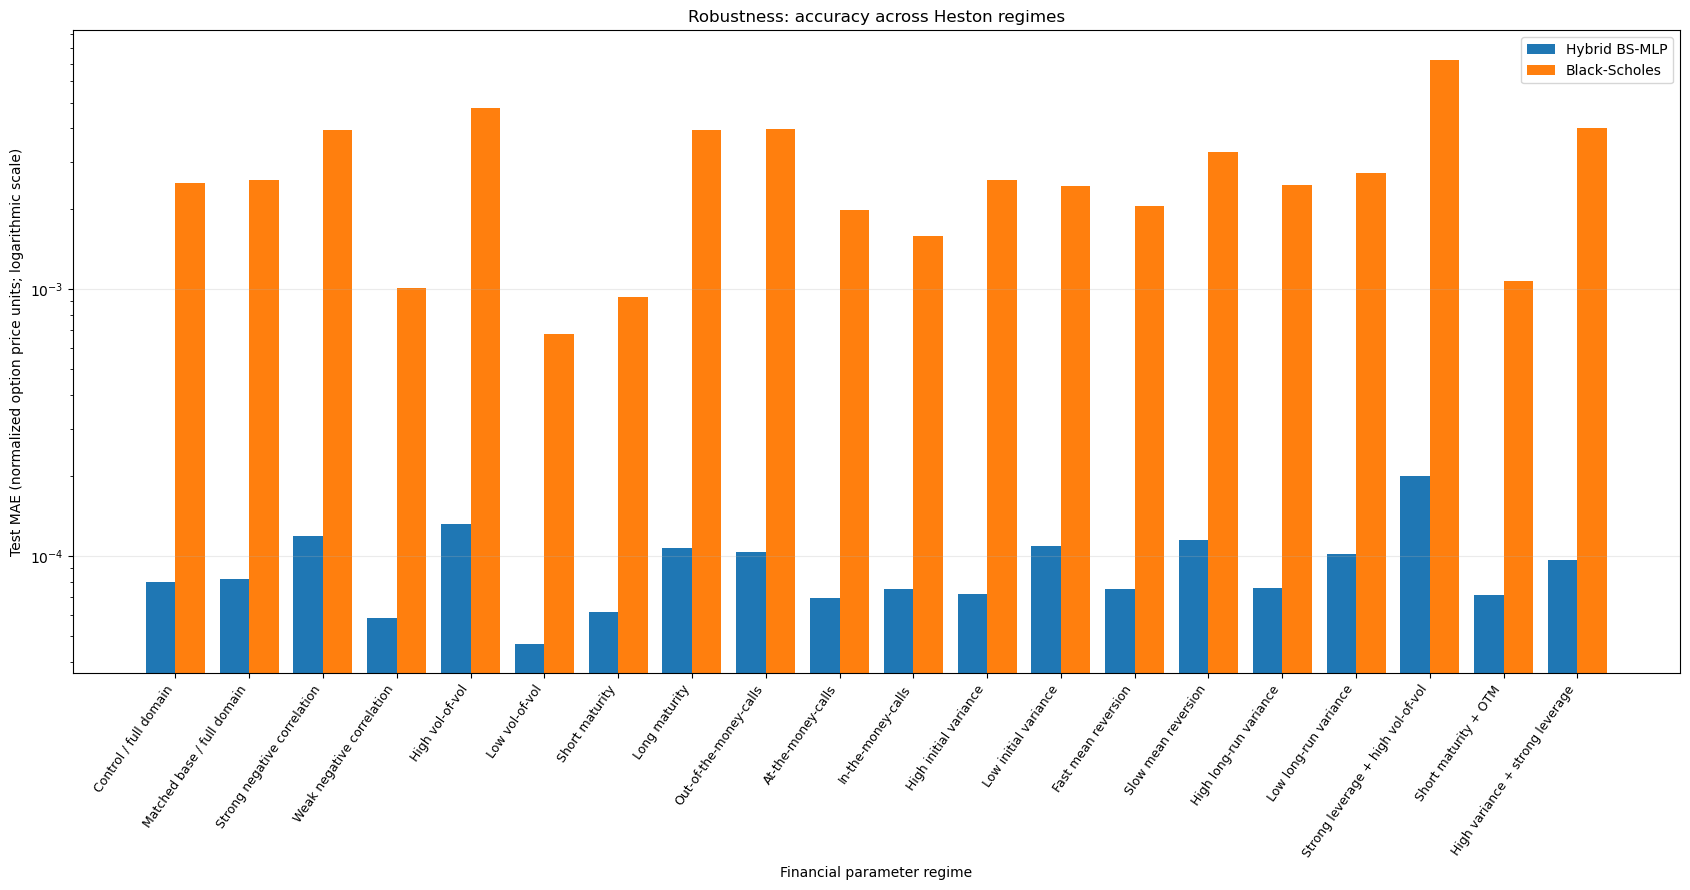

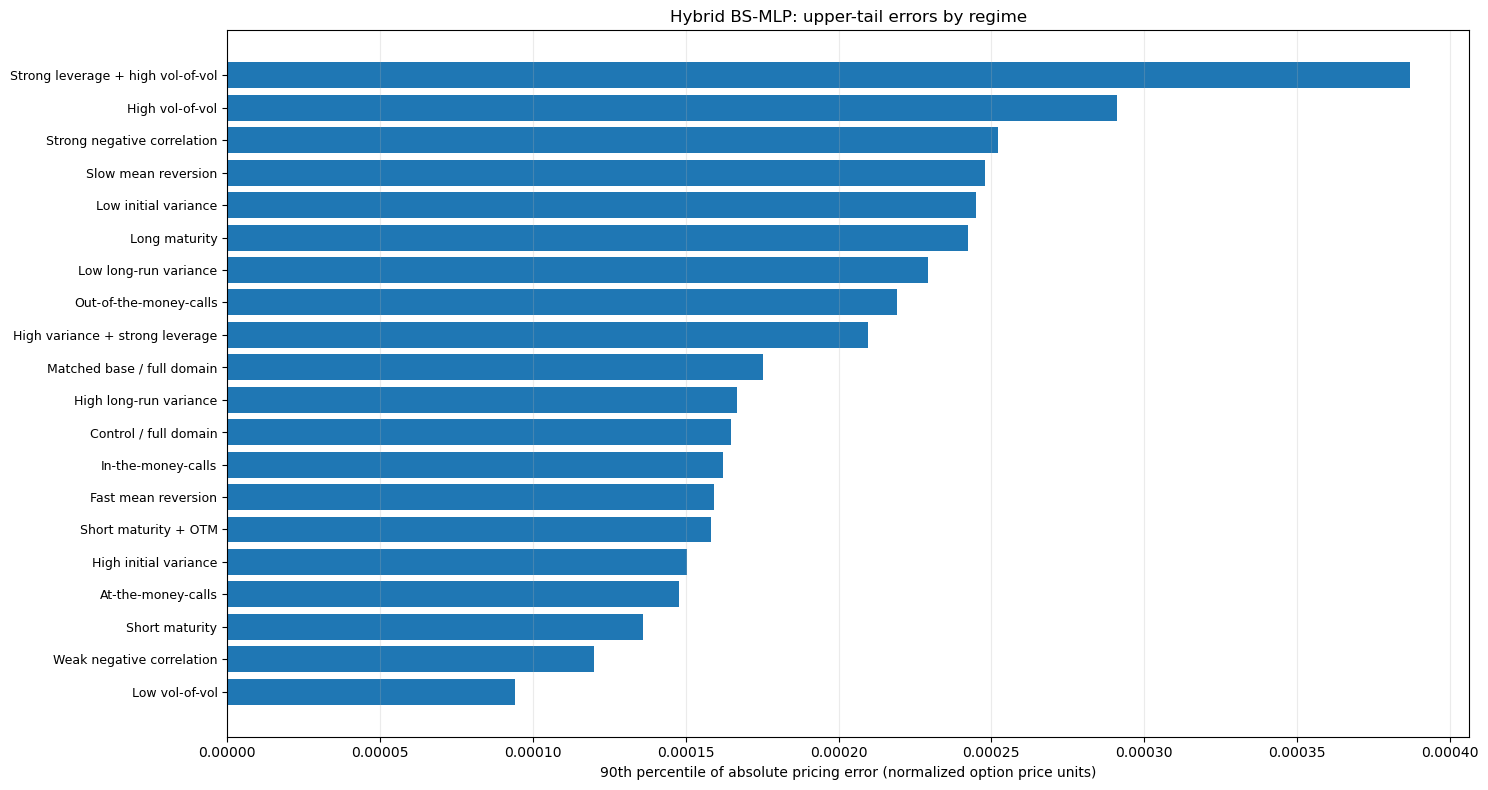

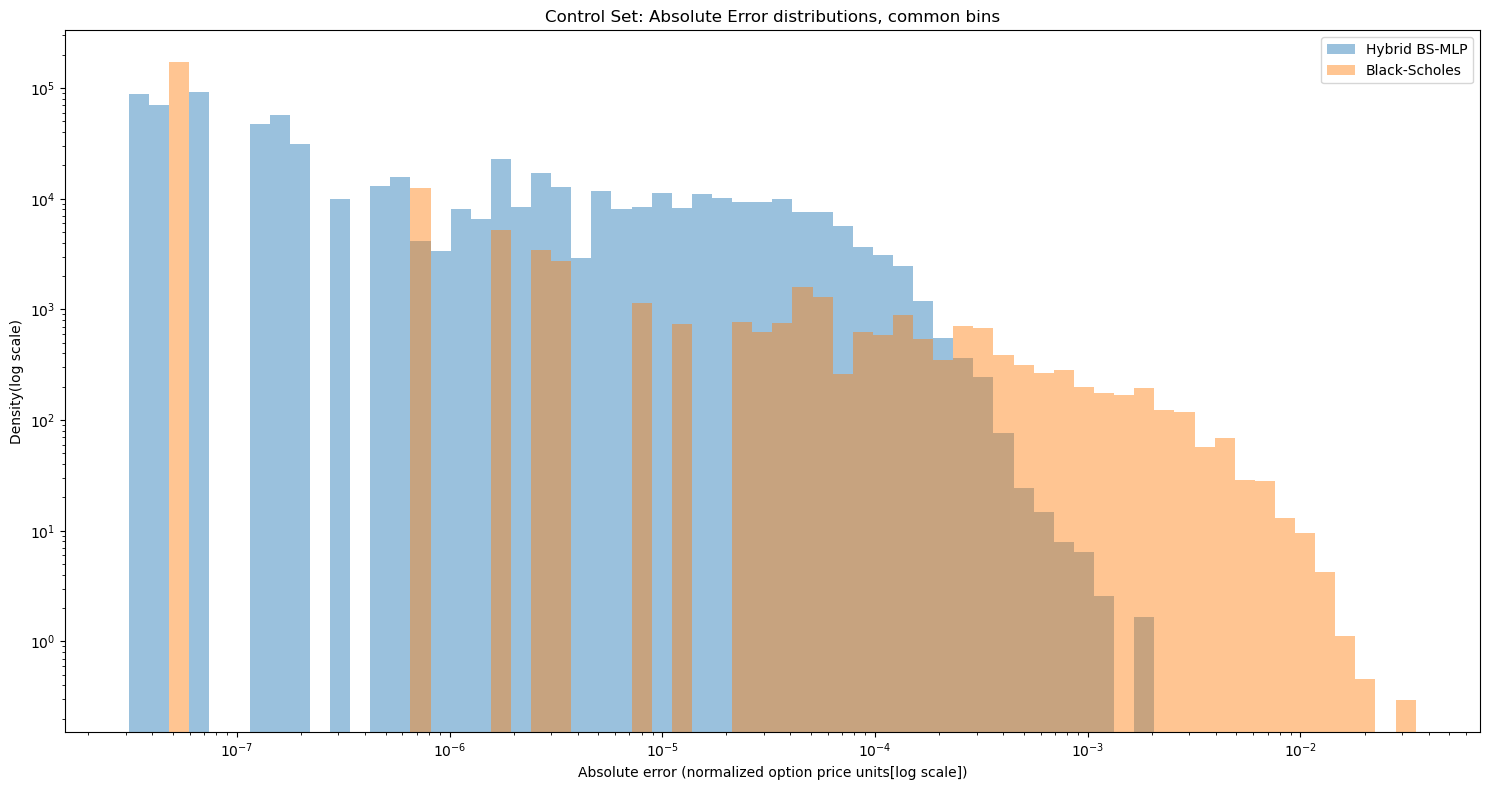

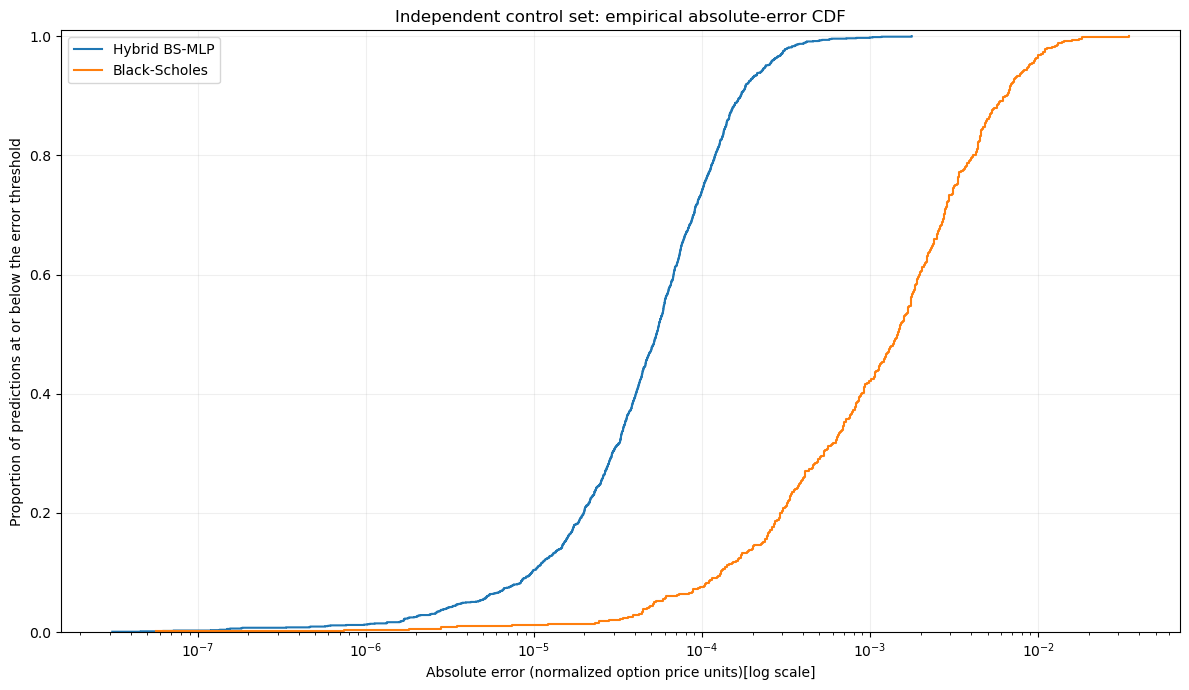


Saved all files to: /Users/john.madhu_/Desktop/MSC_thesis/src/heston/experiment_robustness/n12000/nregime200_control500


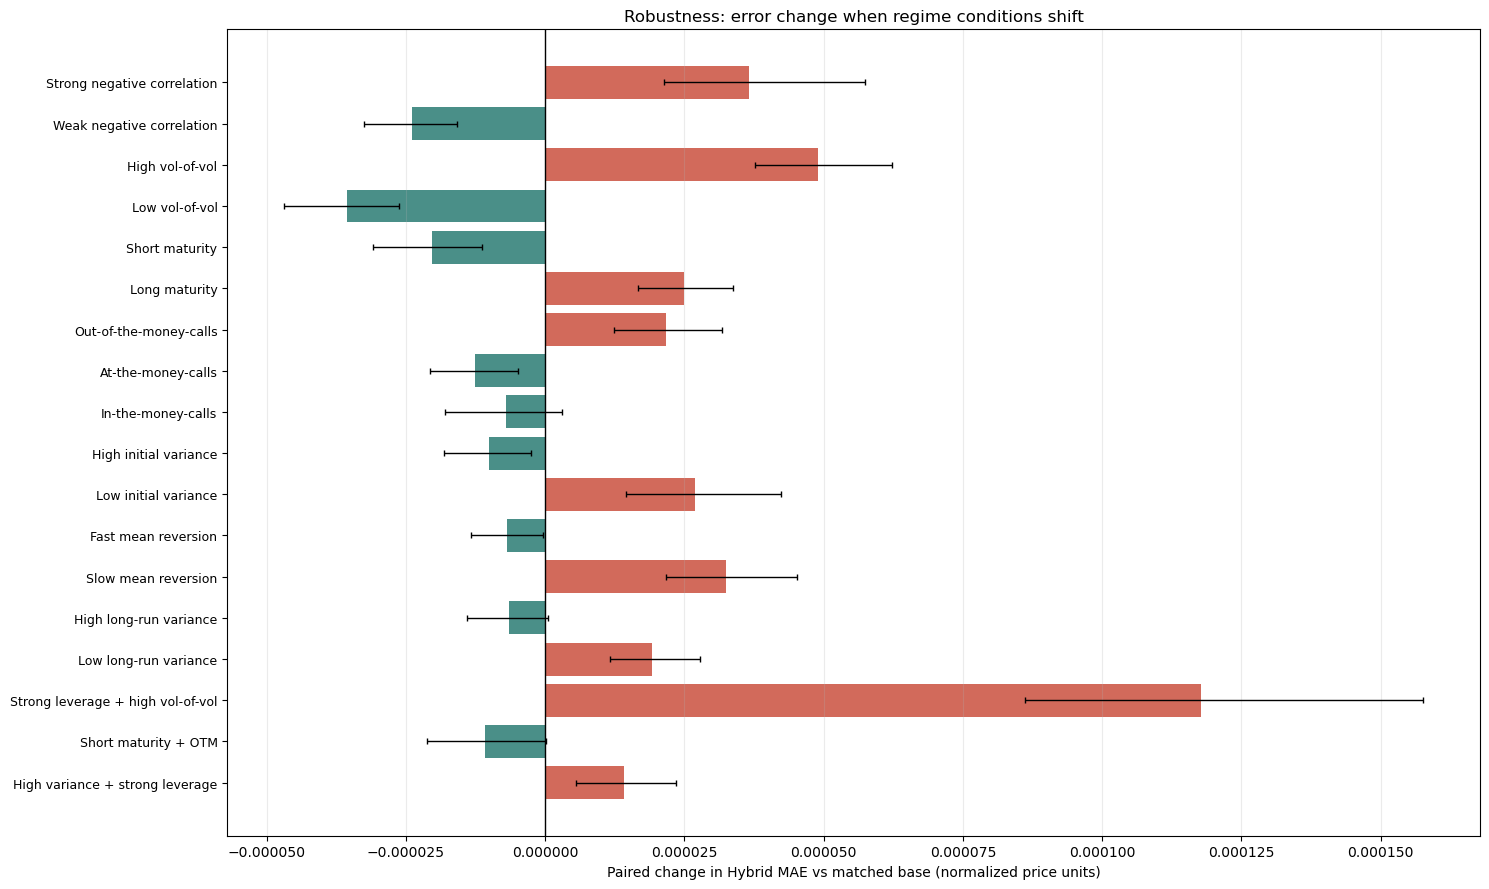

In [41]:
plt.style.use('default')

def save_thesis_figure(fig, filename): 
    fig.set_facecolor('white')
    fig.savefig(FIGURE_DIR / filename, dpi=300, 
                bbox_inches='tight', facecolor='white', transparent=False)
hybrid_preds = predictions.query('model == "Hybrid BS-MLP"').copy()
worst = hybrid_preds.groupby(
    ['case_id', 'regime'], sort=False
).agg(
    mean_absolute_error = ('absolute_error', 'mean'), 
    worst_seed_absolute_error = ('absolute_error', 'max'), 
    true_price = ('price', 'first'), 
    mean_predicted_price = ('predicted_price', 'mean'),
    feller_satisfied=('feller_satisfied', 'first'), 
    **{k: (k, 'first') for k in FEATURES}
).reset_index().sort_values(
    'mean_absolute_error', 
    ascending=False
)
    
worst.head(50).to_csv(OUTPUT_DIR/'hybrid_worst_50_cases.csv', index=False)
print('Largest mean-across-seed Hybrid pricing errors: ')
print(worst.head(12).to_string(index=False, float_format=lambda x:f'{x:.6g}'))

model_order = ['Hybrid BS-MLP', 'MLP Baseline', 'MLP Wide', 'Black-Scholes']
plot_models = [x for x in model_order if x in set(aggregate['model'])]
regime_order = [name for name, _ in REGIMES] 

fig, ax = plt.subplots(figsize=(17,9), facecolor='white')
x = np.arange(len(regime_order))
width = 0.8/len(plot_models)
for j, name in enumerate(plot_models): 
    sub = aggregate[aggregate['model']==name].set_index('regime').reindex(regime_order)
    ax.bar(x-0.4+(j+0.5)*width, sub['mae_mean'], width=width, label=name)
ax.set_yscale('log')
ax.set_ylabel('Test MAE (normalized option price units; logarithmic scale)')
ax.set_xlabel('Financial parameter regime')
ax.set_title('Robustness: accuracy across Heston regimes')
ax.set_xticks(x)
ax.set_xticklabels(regime_order, rotation=55, ha='right', fontsize=9, color='black')
ax.grid(axis='y', alpha=0.25)
ax.legend()
fig.tight_layout()
save_thesis_figure(fig, 'robustness_mae_by_regime.png')
plt.show()
plt.close(fig)


fig, ax = plt.subplots(figsize=(15,8), facecolor='white')
hybrid_sorted = hybrid.reindex(regime_order).sort_values('p90_absolute_error_mean', ascending=False)
bar_labels=list(hybrid_sorted.index[::-1])
ax.barh(np.arange(len(bar_labels)), hybrid_sorted['p90_absolute_error_mean'][::-1])
ax.set_yticks(np.arange(len(bar_labels)))
ax.set_yticklabels(bar_labels, fontsize=9, color='black')
ax.set_xlabel('90th percentile of absolute pricing error (normalized option price units)')
ax.set_title('Hybrid BS-MLP: upper-tail errors by regime')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
save_thesis_figure(fig, 'hybrid_p90_by_regime.png')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(15,8), facecolor='white')
control_errors={}
for name in plot_models: 
    a = predictions[(predictions.model==name) & 
                    (predictions.regime=='Control / full domain')]
    arr = a['absolute_error'].to_numpy(dtype=float)
    arr = arr[np.isfinite(arr) & (arr > 0)]
    if len(arr):
        control_errors[name] = arr
if control_errors:
    pooled = np.concatenate(list(control_errors.values()))
    common_bins=np.geomspace(max(pooled.min(), 1e-12), pooled.max() * 1.001, 65)
    for name, arr in control_errors.items():
        ax.hist(arr, bins=common_bins, alpha=.45, density=True, label=name)
    ax.set_xscale('log')
    ax.set_yscale('log')
ax.set_xlabel('Absolute error (normalized option price units[log scale])')
ax.set_ylabel('Density(log scale)')
ax.set_title('Control Set: Absolute Error distributions, common bins')
ax.legend(frameon=True)
fig.tight_layout()
save_thesis_figure(fig, 'control_absolute_distribution.png')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(12,7), facecolor='white')
for name, arr in control_errors.items():
    sorted_err = np.sort(arr)
    cumulative = np.arange(1, len(sorted_err)+1) / len(sorted_err)
    ax.step(sorted_err, cumulative, where='post', label=name) 
ax.set_xscale('log')
ax.set_ylim(0, 1.01)
ax.set_xlabel('Absolute error (normalized option price units)[log scale]')
ax.set_ylabel('Proportion of predictions at or below the error threshold')
ax.set_title('Independent control set: empirical absolute-error CDF')
ax.legend(frameon=True)
ax.grid(alpha=0.2)
fig.tight_layout()
save_thesis_figure(fig, 'control_absolute_error_ecdf.png')
plt.show()
plt.close(fig)


report = {
    'experiment': 5, 
    'research_questions': ['RQ1', 'RQ4'], 
    'selected_model': 'Hybrid BS-MLP (selected previously by validation MAE)', 
    'model_seeds': MODEL_SEEDS, 
    'train_n': TRAIN_N, 
    'labels': GENERATION_CONFIG, 
    'models_evaluated': ['Black-Scholes']+list(MODELS),
    'model_checkpoint':{
        name: {str(seed):item['path'] for seed, item in seeds.items()} 
        for name, seeds in MODELS.items()
    },
    'test_selection': 'Frozen before robustness evaluation; no tuning on robustness labels', 
    'interpretation_notes': [
        'All default regimes are inside the training bounds but use shifted sampling distribution. ', 
        'Reference failures are reported, not silently dropped. '
        'Seed SD is model initialization variability, not sampling uncertainty', 
        ''
    ] 
}
(OUTPUT_DIR/'robustness_config.json').write_text(json.dumps(report, indent=2, default=str))
print('\nSaved all files to:', OUTPUT_DIR.resolve())

if not paired_stress.empty:
    fig, ax = plt.subplots(figsize=(15,9), facecolor='white')
    h=paired_stress.loc[paired_stress['model']=='Hybrid BS-MLP'].copy()
    h=h.set_index('regime').reindex([n for n,_ in REGIMES[2:]])
    vals=h['mae_stress_minus_matched_base'].to_numpy(dtype=float)
    y = np.arange(len(vals))
    ax.barh(np.arange(len(vals)), vals, color=['#cc5544' if x>0 else '#318078' for x in vals], alpha=0.88)
    lower_ci = h['delta_lower95'].to_numpy(dtype=float)
    upper_ci = h['delta_upper95'].to_numpy(dtype=float)
    xerr = np.vstack([np.maximum(vals - lower_ci, 0.0),
                      np.maximum(upper_ci - vals, 0.0)])
    ax.errorbar(vals, y, xerr=xerr, fmt='none', ecolor='black', elinewidth=1, capsize=2, label='Pointwise 95% bootstrap CI')
    ax.axvline(0, color='black', lw=1)
    ax.set_yticks(y)
    ax.set_yticklabels(h.index, fontsize=9, color='black')
    ax.tick_params(axis='x', labelcolor='black')
    ax.invert_yaxis()
    ax.set_xlabel('Paired change in Hybrid MAE vs matched base (normalized price units)')
    ax.set_title('Robustness: error change when regime conditions shift')
    ax.grid(axis='x', alpha=.25)
    fig.tight_layout()
    save_thesis_figure(fig, 'hybrid_paired_stress_change.png')
    plt.show()
    plt.close(fig)